### Step 1. Installing and Importing Libraries

In [1]:
%pip install tensorflow matplotlib numpy seaborn scikit-learn pillow

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.metrics import classification_report, confusion_matrix

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


### Step 2. Loading the FER2013 Dataset

In [3]:
DATASET_DIR = "FER2013"

TRAIN_DIR = os.path.join(DATASET_DIR, "train")
TEST_DIR = os.path.join(DATASET_DIR, "test")

print("Training folder exists:", os.path.exists(TRAIN_DIR))
print("Testing folder exists:", os.path.exists(TEST_DIR))

print("Emotion categories:", os.listdir(TRAIN_DIR))

Training folder exists: True
Testing folder exists: True
Emotion categories: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']


### Step 3. Loading Images and Creating Training and Validation Sets

In [4]:
IMG_SIZE = (48, 48)
BATCH_SIZE = 64
SEED = 42

train_dataset = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=IMG_SIZE,
    color_mode="grayscale",
    batch_size=BATCH_SIZE,
    validation_split=0.2,
    subset="training",
    seed=SEED
)

validation_dataset = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=IMG_SIZE,
    color_mode="grayscale",
    batch_size=BATCH_SIZE,
    validation_split=0.2,
    subset="validation",
    seed=SEED
)

test_dataset = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=IMG_SIZE,
    color_mode="grayscale",
    batch_size=BATCH_SIZE,
    shuffle=False
)

class_names = train_dataset.class_names

print("Emotion classes:", class_names)
print("Number of classes:", len(class_names))

Found 28709 files belonging to 7 classes.
Using 22968 files for training.
Found 28709 files belonging to 7 classes.
Using 5741 files for validation.
Found 7178 files belonging to 7 classes.
Emotion classes: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
Number of classes: 7


### Step 4. Visualising the Dataset

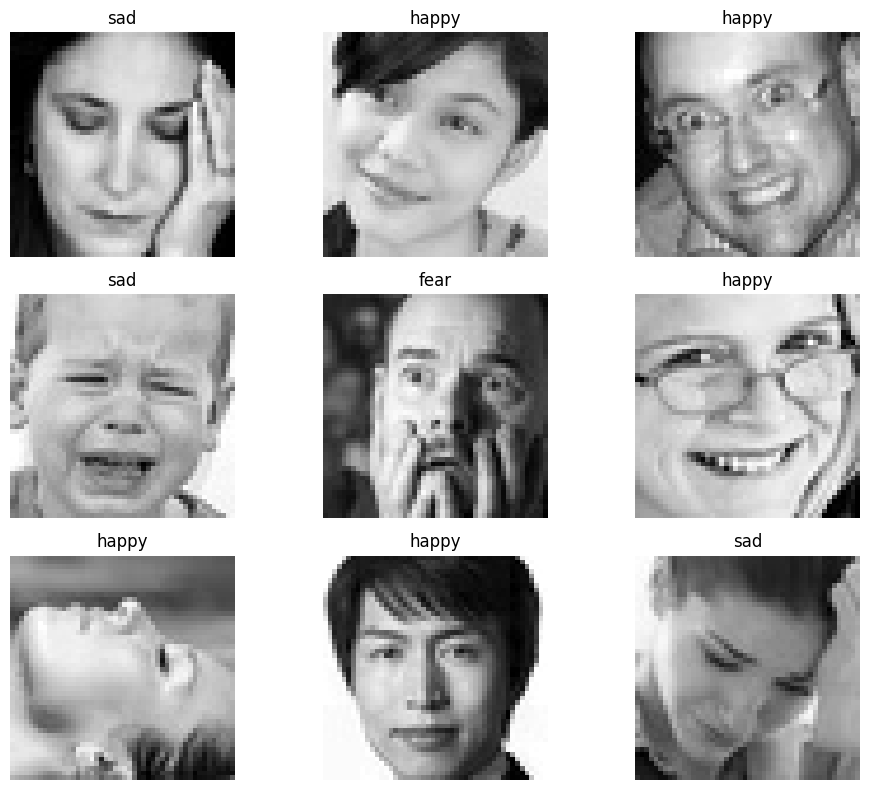

In [5]:
plt.figure(figsize=(10, 8))

for images, labels in train_dataset.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().squeeze(), cmap="gray")
        plt.title(class_names[labels[i].numpy()])
        plt.axis("off")

plt.tight_layout()
plt.show()

### Step 5. Image Preprocessing and Normalisation

In [6]:
AUTOTUNE = tf.data.AUTOTUNE

train_dataset = train_dataset.prefetch(buffer_size=AUTOTUNE)
validation_dataset = validation_dataset.prefetch(buffer_size=AUTOTUNE)
test_dataset = test_dataset.prefetch(buffer_size=AUTOTUNE)

print("Image preprocessing setup completed.")

Image preprocessing setup completed.


### Step 6. Building the CNN Model

In [7]:
model = models.Sequential([

    layers.Input(shape=(48, 48, 1)),

    layers.Rescaling(1./255),

    # First convolution block
    layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),

    # Second convolution block
    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),

    # Third convolution block
    layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),

    # Classification layers
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),

    layers.Dense(7, activation='softmax')
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)                │ (None, 48, 48, 1)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d (Conv2D)                      │ (None, 48, 48, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 24, 24, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 24, 24, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 12, 12, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 12, 12, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 6, 6, 128)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 4608)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         589,952 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 7)                   │             903 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 683,527 (2.61 MB)

 Trainable params: 683,527 (2.61 MB)

 Non-trainable params: 0 (0.00 B)

### Step 7. Compiling the Model

In [8]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("Model compiled successfully!")

Model compiled successfully!


### Step 8. Training the CNN Model

In [10]:
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=20,
    callbacks=[early_stopping]
)

Epoch 1/20
359/359 ━━━━━━━━━━━━━━━━━━━━ 78s 215ms/step - accuracy: 0.5728 - loss: 1.1343 - val_accuracy: 0.5389 - val_loss: 1.2241
Epoch 2/20
359/359 ━━━━━━━━━━━━━━━━━━━━ 33s 93ms/step - accuracy: 0.5829 - loss: 1.0941 - val_accuracy: 0.5351 - val_loss: 1.2262
Epoch 3/20
359/359 ━━━━━━━━━━━━━━━━━━━━ 35s 96ms/step - accuracy: 0.6003 - loss: 1.0539 - val_accuracy: 0.5384 - val_loss: 1.2250
Epoch 4/20
359/359 ━━━━━━━━━━━━━━━━━━━━ 35s 96ms/step - accuracy: 0.6103 - loss: 1.0212 - val_accuracy: 0.5443 - val_loss: 1.2604


### Step 9. Visualising Training Performance

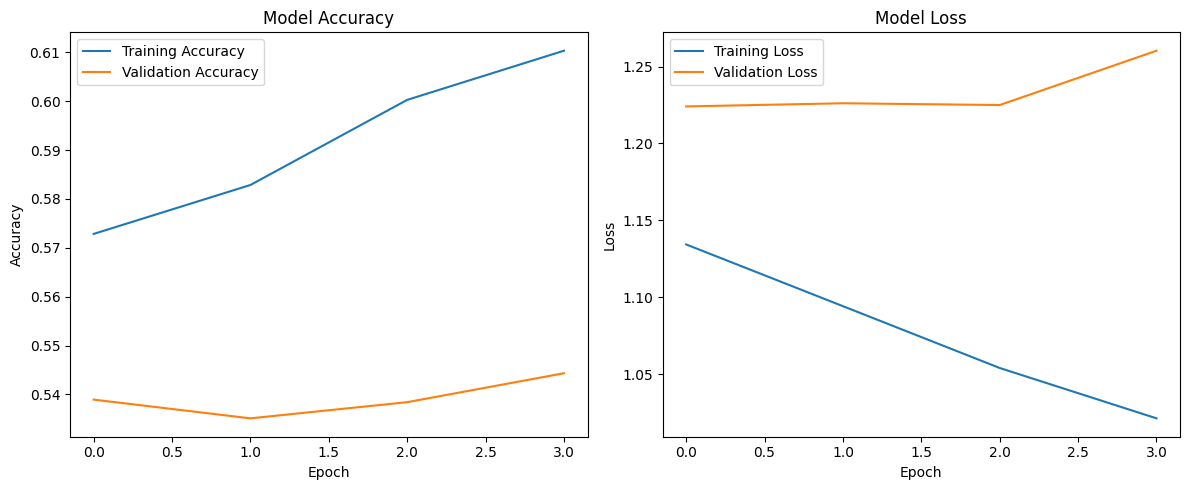

In [11]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

### Step 10. Evaluating the Model

In [12]:
test_loss, test_accuracy = model.evaluate(test_dataset)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy * 100, "%")

113/113 ━━━━━━━━━━━━━━━━━━━━ 4s 33ms/step - accuracy: 0.5357 - loss: 1.2210
Test Loss: 1.2210125923156738
Test Accuracy: 53.56645584106445 %


In [13]:
y_true = []
y_pred = []

for images, labels in test_dataset:
    predictions = model.predict(images, verbose=0)

    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names
))

              precision    recall  f1-score   support

       angry       0.43      0.43      0.43       958
     disgust       0.00      0.00      0.00       111
        fear       0.37      0.32      0.34      1024
       happy       0.75      0.77      0.76      1774
     neutral       0.48      0.52      0.50      1233
         sad       0.39      0.47      0.43      1247
    surprise       0.76      0.62      0.68       831

    accuracy                           0.54      7178
   macro avg       0.45      0.45      0.45      7178
weighted avg       0.53      0.54      0.53      7178



C:\Users\samri\miniconda3\envs\pythonenv\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\samri\miniconda3\envs\pythonenv\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\samri\miniconda3\envs\pythonenv\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is

### Step 11. Confusion Matrix

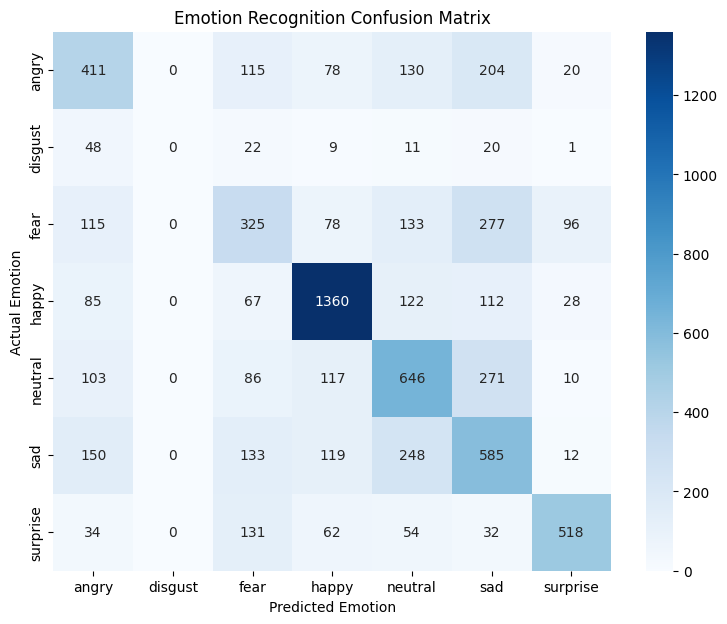

In [14]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Emotion")
plt.ylabel("Actual Emotion")
plt.title("Emotion Recognition Confusion Matrix")

plt.show()

### Step 12. Saving the Trained Model

In [15]:
model.save("emotion_detection_model.keras")

print("Model saved successfully!")

Model saved successfully!


### Step 13. Testing with a New Facial Image

In [16]:
from tensorflow.keras.utils import load_img, img_to_array

image_path = "face.jpg"

img = load_img(
    image_path,
    color_mode="grayscale",
    target_size=(48, 48)
)

img_array = img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)

predictions = model.predict(img_array)

predicted_index = np.argmax(predictions[0])
predicted_emotion = class_names[predicted_index]
confidence = predictions[0][predicted_index] * 100

plt.imshow(img, cmap='gray')
plt.axis('off')
plt.title(
    f"Predicted Expression: {predicted_emotion}\nConfidence: {confidence:.2f}%"
)
plt.show()

print("Predicted Expression:", predicted_emotion)
print("Confidence:", round(confidence, 2), "%")

FileNotFoundError: [Errno 2] No such file or directory: 'face.jpg'